# Task 2.3: reading the qubit through the buffer

**In plain words.** To read the qubit we add a weak drive $\epsilon_Z(a + a^\dagger)$ on the memory. In the $+\alpha$ valley it pushes the light one way, in the $-\alpha$ valley the other way. The pairing term $g_2 a^2 b^\dagger$ passes that push on to the buffer, so the light leaking out of the buffer, $\langle b\rangle$, has opposite sign for the two qubit states. We simulate $\langle b\rangle(t)$ after switching the drive on.

**Prediction before simulating.** For a small drive the response is linear, with steady value $\langle b\rangle \approx -\epsilon_Z/(2g_2\alpha)$. Near one valley, memory and buffer behave like two coupled springs: $\ddot b + (\kappa_b/2)\dot b + 4g_2^2\alpha^2 b = \text{drive}$. That is an under-damped oscillator, so the signal should **ring** before it settles, the same physics as the overshoot in Task 1.1.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/s2').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F          # loads saved results/s2/*.json, draws the figures
from research.s2.notebook_figs import load, nominal, largest
import io
from contextlib import redirect_stdout
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures/s2' / f'{name}.png'), width=w))

In [2]:
with redirect_stdout(io.StringIO()):
    F.readout()

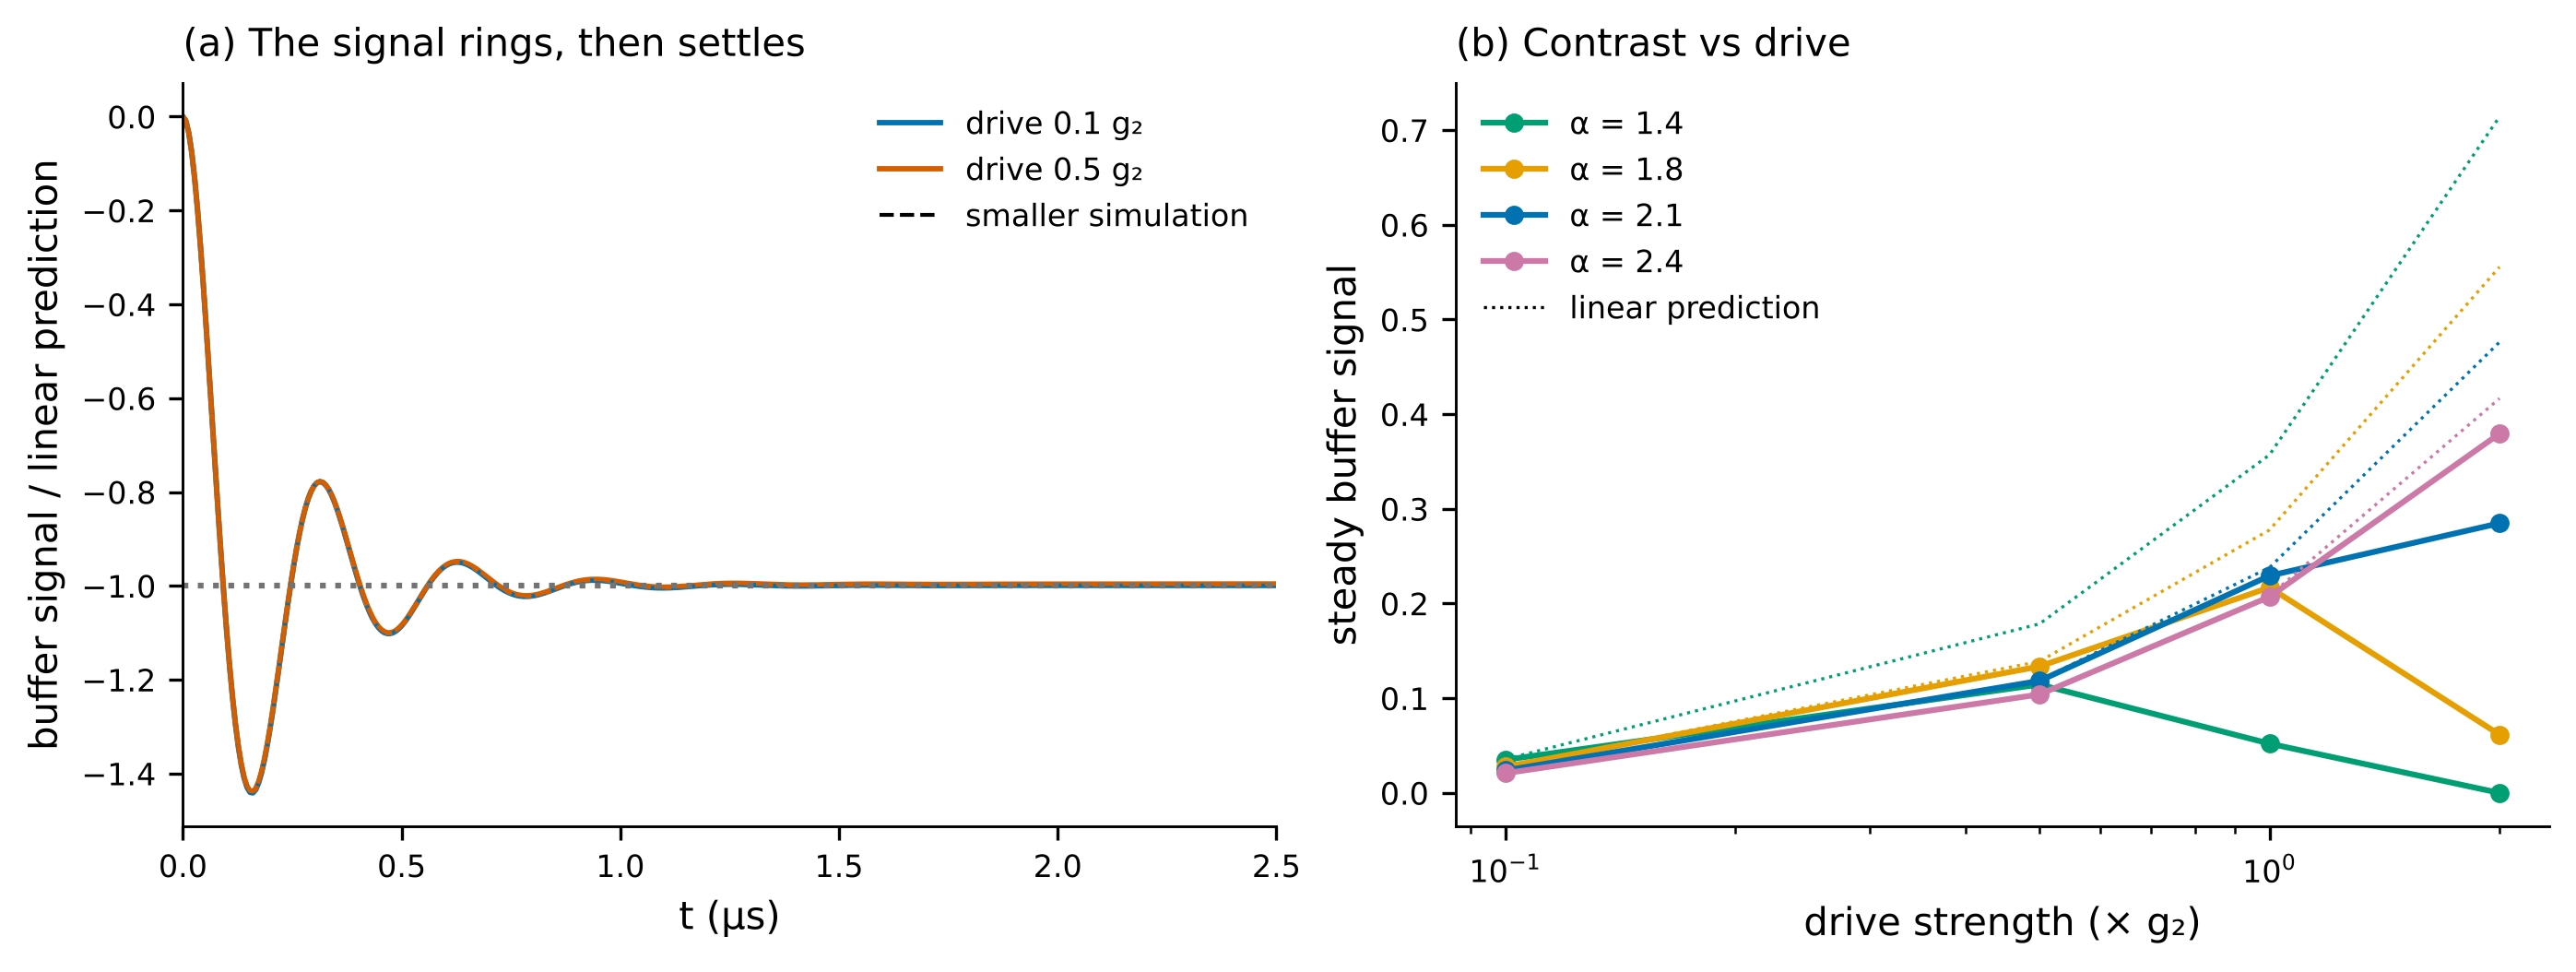

In [3]:
show('task_2_3_readout')

**Buffer signal after switching on the readout drive.** (a) $\mathrm{Re}\langle b\rangle(t)$ for the $+\alpha$ state at $\alpha = 2.1$, divided by the size of the linear prediction, so that $-1$ (dotted) is the linear steady state. Blue and orange are drives of $0.1\,g_2$ and $0.5\,g_2$; solid curves use $36\times10$ levels and dashed curves $32\times8$. All four curves lie on top of each other: the response is linear in the drive and converged in truncation. The signal overshoots by 44% and rings at 3.2 MHz before settling within 1% after about 1 µs. (b) Steady-state $|\langle b\rangle|$ against drive strength for four cat sizes (solid) and the linear prediction (dotted, same colour). Up to about $0.5\,g_2$ the simulation follows the prediction. Beyond that the drive itself causes bit flips fast enough to mix the two qubit states during the 4 µs run, and the contrast collapses, first for the smallest cat.

In [4]:
d = load('readout_a2.10_36x10_T4.json')[0]
pd.DataFrame([{'drive (× g₂)': r['eps_over_g2'], 'ring frequency (MHz)': round(r['ring']['f_MHz'], 2),
               'quality factor': round(r['ring']['Q'], 2), 'settles to 1% in (µs)': round(r['settle_1pct_us'], 2)}
              for r in d['runs'] if r['eps_over_g2'] <= 0.5])

,drive (× g₂),ring frequency (MHz),quality factor,settles to 1% in (µs)
0,0.1,3.21,2.05,0.97
1,0.5,3.21,2.05,0.86


**Result.** The readout works as the linear picture predicts up to about $0.5\,g_2$, but the signal **rings at 3.2 MHz** (quality factor about 2) and needs **about 1 µs** to settle. Waiting for it to settle wastes time during which the qubit can flip; Task 2.4 uses the ringing instead.

## Numerical diagnostics

Largest difference between the $36\times10$ and $32\times8$ signals over the whole 4 µs run, relative to the steady value.

In [5]:
import numpy as np
big, small = load('readout_a2.10_36x10_T4.json')[0], load('readout_a2.10_32x8_T4.json')[0]
rs = {r['eps_over_g2']: r for r in small['runs']}
pd.DataFrame([{'drive (× g₂)': rb['eps_over_g2'],
               'max |difference| / steady': f"{np.max(np.abs(np.array(rb['b_re']) - np.array(rs[rb['eps_over_g2']]['b_re']))) / abs(rb['b_ss_linear']):.1e}"}
              for rb in big['runs']])

,drive (× g₂),max |difference| / steady
0,0.1,4.9e-06
1,0.5,6.3e-06
2,1.0,1.9e-04
3,2.0,4.2e-03
